# Montra Hospitality — Understanding Guest Experience

Montra helps hotels understand their performance. This notebook connects booking, guest, hotel and review data so we can describe guest satisfaction and prepare review text for later analysis.



### 1. Import libraries 

In [1]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

current_folder = Path.cwd().resolve()
if (current_folder / 'data' / 'raw').is_dir():
    PROJECT_ROOT = current_folder
elif (current_folder.parent / 'data' / 'raw').is_dir():
    PROJECT_ROOT = current_folder.parent
else:
    raise FileNotFoundError('Open the notebook from the project root or notebook folder.')

RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 90)
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['figure.dpi'] = 110

print('Project root:', PROJECT_ROOT)

Project root: D:\Amdari\Project_montra


## 2. Data collection

### 2.1 Load the four tables

In [ ]:
USE_DATABASE = False  

if USE_DATABASE:
    from dotenv import load_dotenv
    from sqlalchemy import create_engine, text

    load_dotenv(PROJECT_ROOT / '.env')
    database_url = os.getenv('DATABASE_URL')
    if not database_url:
        raise ValueError('DATABASE_URL is missing. Set it in .env or use USE_DATABASE = True.')

    engine = create_engine(
        database_url,
        pool_pre_ping=True,
        pool_recycle=300,
        connect_args={'connect_timeout': 10},
    )
    try:
        with engine.connect() as connection:
            reviews_raw = pd.read_sql(text('SELECT * FROM reviews'), connection)
            bookings_raw = pd.read_sql(text('SELECT * FROM bookings'), connection)
            guests_raw = pd.read_sql(text('SELECT * FROM guests'), connection)
            hotels_raw = pd.read_sql(text('SELECT * FROM hotels'), connection)
    except Exception:
        raise RuntimeError('Could not read the database. Check the connection or use the CSV snapshots.') from None
    finally:
        engine.dispose()
    print('Data source: PostgreSQL')
else:
    reviews_raw = pd.read_csv(RAW_DIR / 'reviews.csv')
    bookings_raw = pd.read_csv(RAW_DIR / 'bookings.csv')
    guests_raw = pd.read_csv(RAW_DIR / 'guests.csv')
    hotels_raw = pd.read_csv(RAW_DIR / 'hotels.csv')
    print('Data source: CSV snapshots in data/raw/')

Data source: CSV snapshots in data/raw/


In [3]:
raw_tables = {
    'reviews': reviews_raw,
    'bookings': bookings_raw,
    'guests': guests_raw,
    'hotels': hotels_raw,
}

for table_name, table in raw_tables.items():
    print(table_name, '| rows:', len(table), '| columns:', table.shape[1])
    display(table.head(3))

reviews | rows: 35000 | columns: 8


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label
0,1,1,6699,18,"The overall price was fair for what we paid. Might consider it again, might not.",3.2,2025-06-02,neutral
1,2,2,11380,23,The room was nothing out of the ordinary for what we paid. The overall price exceeded ...,4.0,2025-01-22,positive
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recomme...",1.9,2025-03-13,negative


bookings | rows: 35000 | columns: 9


,booking_id,guest_id,hotel_id,room_type,booking_channel,check_in_date,check_out_date,total_amount,stay_duration
0,1,6699,18,Suite,Direct Website,2025-05-25,2025-05-26,296.44,1
1,2,11380,23,Deluxe,Corporate Portal,2025-01-09,2025-01-13,483.56,4
2,3,4812,13,Executive,Travel Agent,2025-03-04,2025-03-06,415.59,2


guests | rows: 12000 | columns: 5


,guest_id,customer_type,loyalty_status,country,previous_stays
0,1,Leisure,NaN,Australia,0
1,2,Leisure,NaN,Germany,1
2,3,Business,Gold,United Kingdom,0


hotels | rows: 25 | columns: 5


,hotel_id,hotel_name,location,star_rating,total_rooms
0,1,The Birmingham Grand,Birmingham,4,254
1,2,The London Heritage,London,5,234
2,3,The Oxford Boutique,Oxford,3,146


There are **35,000 reviews (8 columns)**, **35,000 bookings (9 columns)**, **12,000 guests (5 columns)** and **25 hotels (5 columns)**. The different table sizes reflect different types of records; they are not a reason to remove rows.


### 2.2 Column types and missing values

In [4]:
for table_name, table in raw_tables.items():
    print('\nTable:', table_name)
    table.info()
    display(table.isna().sum().rename('missing_values').to_frame())
    print('Exact duplicate rows:', table.duplicated().sum())


Table: reviews
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   review_id        35000 non-null  int64  
 1   booking_id       35000 non-null  int64  
 2   guest_id         35000 non-null  int64  
 3   hotel_id         35000 non-null  int64  
 4   review_text      35000 non-null  object 
 5   rating_score     35000 non-null  float64
 6   review_date      35000 non-null  object 
 7   sentiment_label  35000 non-null  object 
dtypes: float64(1), int64(4), object(3)
memory usage: 2.1+ MB


,missing_values
review_id,0
booking_id,0
guest_id,0
hotel_id,0
review_text,0
rating_score,0
review_date,0
sentiment_label,0


Exact duplicate rows: 0

Table: bookings
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   booking_id       35000 non-null  int64  
 1   guest_id         35000 non-null  int64  
 2   hotel_id         35000 non-null  int64  
 3   room_type        35000 non-null  object 
 4   booking_channel  35000 non-null  object 
 5   check_in_date    35000 non-null  object 
 6   check_out_date   35000 non-null  object 
 7   total_amount     35000 non-null  float64
 8   stay_duration    35000 non-null  int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 2.4+ MB


,missing_values
booking_id,0
guest_id,0
hotel_id,0
room_type,0
booking_channel,0
check_in_date,0
check_out_date,0
total_amount,0
stay_duration,0


Exact duplicate rows: 0

Table: guests
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   guest_id        12000 non-null  int64 
 1   customer_type   12000 non-null  object
 2   loyalty_status  5964 non-null   object
 3   country         12000 non-null  object
 4   previous_stays  12000 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 468.9+ KB


,missing_values
guest_id,0
customer_type,0
loyalty_status,6036
country,0
previous_stays,0


Exact duplicate rows: 0

Table: hotels
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   hotel_id     25 non-null     int64 
 1   hotel_name   25 non-null     object
 2   location     25 non-null     object
 3   star_rating  25 non-null     int64 
 4   total_rooms  25 non-null     int64 
dtypes: int64(3), object(2)
memory usage: 1.1+ KB


,missing_values
hotel_id,0
hotel_name,0
location,0
star_rating,0
total_rooms,0


Exact duplicate rows: 0


The only missing source field is `loyalty_status`: **6,036 of 12,000 guest records**. Dates are initially loaded as text. There are no exact duplicate rows in the four source tables.

## 3. Data cleaning and preparation
We clean the source tables first, check that their links are valid, and then join them. A **join** adds fields from another table using a shared ID.


### 3.1 Remove exact duplicate records

In [5]:
reviews = reviews_raw.copy()
bookings = bookings_raw.copy()
guests = guests_raw.copy()
hotels = hotels_raw.copy()

clean_tables = {'reviews': reviews, 'bookings': bookings, 'guests': guests, 'hotels': hotels}
for table_name, table in clean_tables.items():
    rows_before = len(table)
    table.drop_duplicates(inplace=True)
    print(table_name, '| exact duplicates removed:', rows_before - len(table))

reviews | exact duplicates removed: 0
bookings | exact duplicates removed: 0
guests | exact duplicates removed: 0
hotels | exact duplicates removed: 0


No rows are removed from the supplied snapshots. This check prepares the notebook for exact repeated records if they appear in a later extract.


### 3.2 Standardise categories and handle missing loyalty status

In [37]:
for table in clean_tables.values():
    text_columns = table.select_dtypes(include=['object', 'string']).columns # select text columns
    for column in text_columns:
        if column != 'review_text':
            table[column] = table[column].astype('string').str.strip() # remove spaces at the start and end
            table[column] = table[column].replace('', pd.NA)

reviews['sentiment_label'] = reviews['sentiment_label'].str.lower()
missing_loyalty = guests['loyalty_status'].isna().sum()
guests['loyalty_status'] = guests['loyalty_status'].fillna('Unknown') # fill loyalty with unknown

print('Guest records labelled Unknown:', missing_loyalty)
print('Sentiment categories:', reviews['sentiment_label'].unique())
display(guests['loyalty_status'].value_counts().rename('guests').to_frame())

Guest records labelled Unknown: 0
Sentiment categories: <StringArray>
['neutral', 'positive', 'negative']
Length: 3, dtype: string


,guests
loyalty_status,
Unknown,6036
Silver,2951
Gold,1998
Platinum,1015


The **6,036 missing guest loyalty records** now have an explicit “Unknown” category. The existing sentiment categories are `negative`, `neutral` and `positive`. The data owner should confirm whether the missing loyalty field means non-membership or unrecorded information.


### 3.3 Convert dates and numeric fields

**What this code does**

- `to_datetime()` turns date text into dates that Python can compare and subtract.
- `to_numeric()` makes sure amounts and scores are numbers.
- `errors="coerce"` turns an unreadable value into a missing value; the next checks will catch it rather than silently using it.
- Calculate the stay length from check-out minus check-in for comparison with the supplied duration.

In [38]:
# Turn text into dates
reviews['review_date'] = pd.to_datetime(reviews['review_date'], errors='coerce')
bookings['check_in_date'] = pd.to_datetime(bookings['check_in_date'], errors='coerce')
bookings['check_out_date'] = pd.to_datetime(bookings['check_out_date'], errors='coerce')

# Ensure amounts and scores are numbers
reviews['rating_score'] = pd.to_numeric(reviews['rating_score'], errors='coerce') # coerce to turn unreadable value into missing value
bookings['total_amount'] = pd.to_numeric(bookings['total_amount'], errors='coerce')
bookings['stay_duration'] = pd.to_numeric(bookings['stay_duration'], errors='coerce')
guests['previous_stays'] = pd.to_numeric(guests['previous_stays'], errors='coerce')
hotels['star_rating'] = pd.to_numeric(hotels['star_rating'], errors='coerce')
hotels['total_rooms'] = pd.to_numeric(hotels['total_rooms'], errors='coerce')

calculated_nights = (bookings['check_out_date'] - bookings['check_in_date']).dt.days
print('Date types:', reviews['review_date'].dtype, bookings['check_in_date'].dtype)
display(bookings[['check_in_date', 'check_out_date', 'stay_duration']].head())

Date types: datetime64[ns] datetime64[ns]


,check_in_date,check_out_date,stay_duration
0,2025-05-25,2025-05-26,1
1,2025-01-09,2025-01-13,4
2,2025-03-04,2025-03-06,2
3,2026-03-06,2026-03-09,3
4,2025-02-25,2025-03-02,5


All source dates and numeric values convert successfully. The date fields are now suitable for monthly trends and stay-duration checks.


### 3.4 Check IDs and links between tables

In [39]:
primary_keys = {'reviews': 'review_id', 'bookings': 'booking_id', 'guests': 'guest_id', 'hotels': 'hotel_id'} # identify one row in each table
for table_name, table in clean_tables.items():
    key = primary_keys[table_name]
    assert table[key].notna().all(), f'{table_name}: missing {key}'
    assert table[key].is_unique, f'{table_name}: repeated {key}; investigate before joining'

link_checks = pd.DataFrame({
    'check': [
        'Review booking exists', 'Review guest exists', 'Review hotel exists',
        'Booking guest exists', 'Booking hotel exists',
    ],
    'unmatched_rows': [
        (~reviews['booking_id'].isin(bookings['booking_id'])).sum(),
        (~reviews['guest_id'].isin(guests['guest_id'])).sum(),
        (~reviews['hotel_id'].isin(hotels['hotel_id'])).sum(),
        (~bookings['guest_id'].isin(guests['guest_id'])).sum(),
        (~bookings['hotel_id'].isin(hotels['hotel_id'])).sum(),
    ],
})
display(link_checks)
assert link_checks['unmatched_rows'].sum() == 0, 'Unmatched IDs found; investigate source records.'

,check,unmatched_rows
0,Review booking exists,0
1,Review guest exists,0
2,Review hotel exists,0
3,Booking guest exists,0
4,Booking hotel exists,0


All primary keys are present and unique. **All five link checks return zero unmatched rows**. Every review and booking can be linked to its recorded guest and hotel.


### 3.5 Check ratings, dates, text and booking values

In [9]:
validity = pd.DataFrame({
    'rule': [
        'Rating is between 1 and 5', 'Review text is present and not blank',
        'Sentiment is negative, neutral or positive', 'Review date is readable',
        'Booking dates are readable', 'Stay duration is positive',
        'Stay duration agrees with dates', 'Booking amount is positive',
        'Previous stays is non-negative', 'Hotel star rating is between 1 and 5',
        'Hotel room count is positive',
    ],
    'invalid_rows': [
        (~reviews['rating_score'].between(1, 5)).sum(),
        reviews['review_text'].fillna('').str.strip().eq('').sum(),
        (~reviews['sentiment_label'].isin(['negative', 'neutral', 'positive'])).sum(),
        reviews['review_date'].isna().sum(),
        bookings[['check_in_date', 'check_out_date']].isna().any(axis=1).sum(),
        (~bookings['stay_duration'].gt(0)).sum(),
        (bookings['stay_duration'] != calculated_nights).sum(),
        (~bookings['total_amount'].gt(0)).sum(),
        (~guests['previous_stays'].ge(0)).sum(),
        (~hotels['star_rating'].between(1, 5)).sum(),
        (~hotels['total_rooms'].gt(0)).sum(),
    ],
})
display(validity)
assert validity['invalid_rows'].sum() == 0, 'Invalid records found. Review these before continuing.'

,rule,invalid_rows
0,Rating is between 1 and 5,0
1,Review text is present and not blank,0
2,"Sentiment is negative, neutral or positive",0
3,Review date is readable,0
4,Booking dates are readable,0
5,Stay duration is positive,0
6,Stay duration agrees with dates,0
7,Booking amount is positive,0
8,Previous stays is non-negative,0
9,Hotel star rating is between 1 and 5,0


**All 11 validity checks pass**. Scores are within 1–5, text is available, dates parse, stay duration matches the dates, and booking amounts are positive. No score, amount or date needs an invented replacement.

### 3.6 Join booking, guest and hotel IDs 

In [10]:
booking_links = reviews.merge(
    bookings[['booking_id', 'guest_id', 'hotel_id']],
    on='booking_id',
    how='left',
    suffixes=('', '_booking'),
    validate='many_to_one',
)

guest_mismatches = (booking_links['guest_id'] != booking_links['guest_id_booking']).sum()
hotel_mismatches = (booking_links['hotel_id'] != booking_links['hotel_id_booking']).sum()

print('Guest ID mismatches:', guest_mismatches)
print('Hotel ID mismatches:', hotel_mismatches)
print('Additional reviews sharing a booking ID:', reviews['booking_id'].duplicated().sum())
assert guest_mismatches == 0 and hotel_mismatches == 0, 'Review and booking context do not match.'

Guest ID mismatches: 0
Hotel ID mismatches: 0
Additional reviews sharing a booking ID: 0


There are **zero guest or hotel mismatches**, and no booking ID repeats in the reviews. 

### 3.7 Join the cleaned tables and check review timing

In [11]:
booking_details = bookings.drop(columns=['guest_id', 'hotel_id'])
analysis = reviews.merge(booking_details, on='booking_id', how='left', validate='many_to_one')
analysis = analysis.merge(guests, on='guest_id', how='left', validate='many_to_one')
analysis = analysis.merge(hotels, on='hotel_id', how='left', validate='many_to_one')

assert len(analysis) == len(reviews), 'The joins changed the number of review rows.'
print('Joined table before extra features:', analysis.shape)
print('Remaining missing values:', analysis.isna().sum().sum())
assert not analysis.isna().any().any(), 'Missing joined fields remain; investigate before analysis.'

analysis['days_to_review'] = (analysis['review_date'] - analysis['check_out_date']).dt.days
assert analysis['days_to_review'].ge(0).all(), 'Some reviews are dated before check-out.'
display(analysis['days_to_review'].describe().round(1).to_frame())

Joined table before extra features: (35000, 22)
Remaining missing values: 0


,days_to_review
count,35000.0
mean,7.0
std,4.3
min,0.0
25%,3.0
50%,7.0
75%,11.0
max,14.0


The joins produce **35,000 rows × 22 source columns**, with no lost or duplicated reviews and no remaining missing fields. Reviews were posted **0–14 days after check-out**, with a median delay of **7 days**.

### 3.8 Hotels that share a name

In [12]:
shared_names = hotels[hotels['hotel_name'].duplicated(keep=False)]
display(shared_names)

analysis['hotel_label'] = analysis['hotel_name'] + ' (#' + analysis['hotel_id'].astype(str) + ')'
print('Unique hotel IDs:', analysis['hotel_id'].nunique())
print('Unique hotel names:', analysis['hotel_name'].nunique())

,hotel_id,hotel_name,location,star_rating,total_rooms
8,9,Edinburgh Riverside Hotel,Edinburgh,3,71
13,14,Edinburgh Riverside Hotel,Edinburgh,3,215


Unique hotel IDs: 25
Unique hotel names: 24


There are **25 hotel IDs but 24 unique hotel names**. Hotels **#9 and #14** are both called **Edinburgh Riverside Hotel**. Adding the ID to the display label prevents these two properties from appearing as one hotel.

### 3.9 Clean the review text

In [ ]:
analysis['text_clean'] = analysis['review_text'].str.replace('’', "'", regex=False)
analysis['text_clean'] = analysis['text_clean'].str.replace('‘', "'", regex=False) # create text_clean converting to lowercase, removingextrawhitespace and trimming the ends
analysis['text_clean'] = analysis['text_clean'].str.lower()
analysis['text_clean'] = analysis['text_clean'].str.replace(r'\s+', ' ', regex=True).str.strip()

assert analysis['text_clean'].str.len().gt(0).all(), 'Empty text after cleaning.'
display(analysis[['review_id', 'review_text', 'text_clean']].head(3))

,review_id,review_text,text_clean
0,1,"The overall price was fair for what we paid. Might consider it again, might not.","the overall price was fair for what we paid. might consider it again, might not."
1,2,The room was nothing out of the ordinary for what we paid. The overall price exceeded ...,the room was nothing out of the ordinary for what we paid. the overall price exceeded ...
2,3,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recomme...","unfortunately, the pool was outdated — it clearly needed some upkeep. wouldn't recomme..."


: 

The cleaning makes formatting consistent while preserving the original wording

### 3.10 Flag repeated text and rating–label disagreements

In [14]:
analysis['repeated_text'] = analysis['text_clean'].duplicated(keep=False)
analysis['rating_band'] = pd.cut(
    analysis['rating_score'],
    bins=[0, 2.5, 3.5, 5.01],
    labels=['negative', 'neutral', 'positive'],
    right=False,
)
analysis['label_rating_disagreement'] = analysis['sentiment_label'] != analysis['rating_band']

print('Reviews in repeated-text groups:', analysis['repeated_text'].sum())
print('Unique cleaned review texts:', analysis['text_clean'].nunique())
print('Rating-band / label disagreements:', analysis['label_rating_disagreement'].sum())

Reviews in repeated-text groups: 829
Unique cleaned review texts: 34536
Rating-band / label disagreements: 1871


829 review rows belong to repeated-text groups, and there are **34,536 unique complete cleaned texts**. 1,871 reviews disagree with the chosen rating bands. Different IDs can carry identical wording, so repeated text is flagged and retained. Disagreement is a review flag, not proof of incorrect labelling.


In [15]:
analysis['review_month'] = analysis['review_date'].dt.strftime('%Y-%m')
analysis['word_count'] = analysis['review_text'].str.split().str.len()
analysis['character_count'] = analysis['review_text'].str.len()
analysis['sentence_count_approx'] = analysis['review_text'].str.count(r'[.!?](?:\s|$)')
analysis['is_negative'] = analysis['sentiment_label'].eq('negative')

display(analysis[['review_month', 'word_count', 'sentence_count_approx', 'is_negative']].head())
print('Review period:', analysis['review_date'].min().date(), 'to', analysis['review_date'].max().date())
print('Hotels:', analysis['hotel_id'].nunique(), '| cities:', analysis['location'].nunique())
print('Guests with a review:', analysis['guest_id'].nunique())
print('Review rows with Unknown loyalty:', analysis['loyalty_status'].eq('Unknown').sum())

,review_month,word_count,sentence_count_approx,is_negative
0,2025-06,15,2,False
1,2025-01,29,2,False
2,2025-03,16,2,True
3,2026-03,21,2,True
4,2025-03,39,3,False


Review period: 2025-01-02 to 2026-06-30
Hotels: 25 | cities: 14
Guests with a review: 11377
Review rows with Unknown loyalty: 17615


Reviews cover **2 January 2025–30 June 2026**, across **25 hotels in 14 cities**, and **11,377 guests**. There are **17,615 review rows** with Unknown loyalty; this is higher than 6,036 guest records because guests can have several bookings and reviews.

### 3.11 Separate unique-text dataset for future use

In [16]:
labels_per_text = analysis.groupby('text_clean')['sentiment_label'].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1].index
analysis['text_label_conflict'] = analysis['text_clean'].isin(conflicting_texts)

text_columns = [
    'review_id', 'review_text', 'text_clean', 'rating_score',
    'sentiment_label', 'label_rating_disagreement',
]
text_prepared = analysis.loc[~analysis['text_label_conflict'], text_columns].copy()
text_prepared = text_prepared.drop_duplicates(subset='text_clean')

print('Complete texts with conflicting labels:', len(conflicting_texts))
print('Review rows carrying those texts:', analysis['text_label_conflict'].sum())
print('Rows in the unique-text preparation file:', len(text_prepared))
print('Rows retained for business analysis:', len(analysis))
assert text_prepared['text_clean'].is_unique

Complete texts with conflicting labels: 76
Review rows carrying those texts: 196
Rows in the unique-text preparation file: 34460
Rows retained for business analysis: 35000


**76 complete-text groups (196 review rows)** carry more than one sentiment label. The separate preparation file contains **34,460 unique texts**, while the analysis still includes **35,000 reviews**. Removing repeated complete reviews helps later splitting, but common sentences can still occur across different reviews; this does not guarantee a leakage-free future evaluation.

### 3.13 Save the prepared data 

In [17]:
analysis.to_csv(PROCESSED_DIR / 'reviews_prepared.csv', index=False)
text_prepared.to_csv(PROCESSED_DIR / 'review_text_prepared.csv', index=False)
bookings.to_csv(PROCESSED_DIR / 'bookings_prepared.csv', index=False)
guests.to_csv(PROCESSED_DIR / 'guests_prepared.csv', index=False)
hotels.to_csv(PROCESSED_DIR / 'hotels_prepared.csv', index=False)
validity.to_csv(PROCESSED_DIR / 'data_quality_checks.csv', index=False)

print('Prepared review table:', analysis.shape)
print('Unique-text file:', text_prepared.shape)
print('Saved prepared files in:', PROCESSED_DIR)

Prepared review table: (35000, 34)
Unique-text file: (34460, 6)
Saved prepared files in: D:\Amdari\Project_montra\data\processed


The prepared review table has **35,000 rows** and includes context, original text, cleaned text and quality flags. The raw CSVs remain available for comparison. We can now perform EDA on checked data.

## 4. EDA

### 4.1 Room-type booking volumes 

,bookings,share_percent
room_type,,
Standard,10596,30.3
Deluxe,8619,24.6
Executive,5293,15.1
Family Room,4137,11.8
Suite,3544,10.1
Twin,2811,8.0


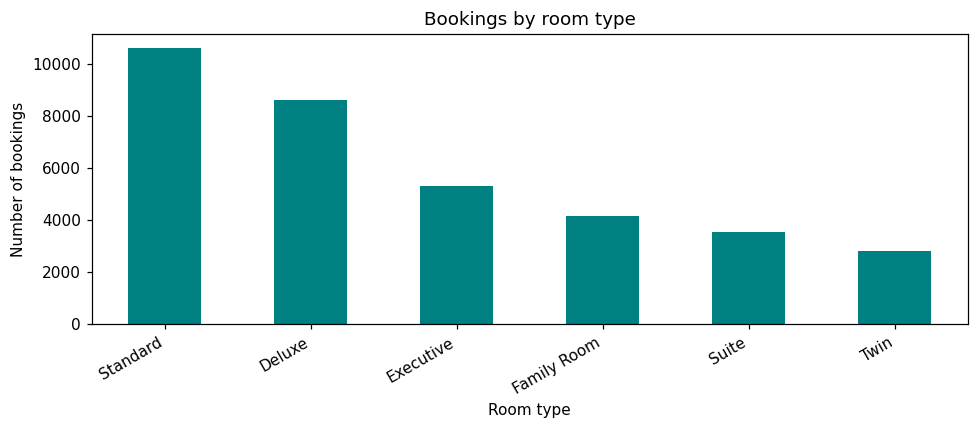

In [18]:
room_counts = bookings['room_type'].value_counts()
room_volume = room_counts.rename('bookings').to_frame()
room_volume['share_percent'] = 100 * room_volume['bookings'] / len(bookings)
display(room_volume.round(1))

room_counts.plot(kind='bar', color='teal')
plt.title('Bookings by room type')
plt.xlabel('Room type')
plt.ylabel('Number of bookings')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Standard rooms are the most booked: 10,596 bookings (30.3%)**, followed by Deluxe with **8,619 (24.6%)**. Suites account for **3,544 bookings (10.1%)**. Volume shows demand mix; it does not show which rooms earn the most.


### 4.2 Booking value by room type

,bookings,total_booking_value,average_booking_value,value_share_percent
room_type,,,,
Deluxe,8619,3938732.66,456.98,24.15
Executive,5293,3211430.94,606.73,19.69
Standard,10596,3112788.77,293.77,19.08
Suite,3544,3029593.14,854.85,18.57
Family Room,4137,2158312.62,521.71,13.23
Twin,2811,861141.58,306.35,5.28


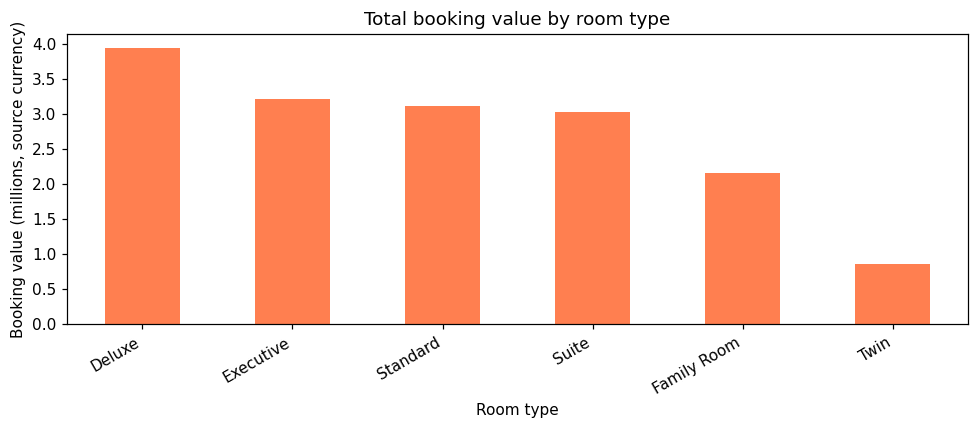

Total booking value: 16311999.71


In [19]:
room_value = bookings.groupby('room_type').agg(
    bookings=('booking_id', 'count'),
    total_booking_value=('total_amount', 'sum'),
    average_booking_value=('total_amount', 'mean'),
)
room_value['value_share_percent'] = 100 * room_value['total_booking_value'] / bookings['total_amount'].sum()
room_value = room_value.sort_values('total_booking_value', ascending=False)
display(room_value.round(2))

(room_value['total_booking_value'] / 1_000_000).plot(kind='bar', color='coral')
plt.title('Total booking value by room type')
plt.xlabel('Room type')
plt.ylabel('Booking value (millions, source currency)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()
print('Total booking value:', round(bookings['total_amount'].sum(), 2))

Total booking value is **16,311,999.71** in source-currency units. **Deluxe** contributes the most: **3.94 million (24.1%)**. **Suites** generate **3.03 million (18.6%)** from only 10.1% of bookings, with an average booking value of **854.85**. Standard rooms average **293.77** per booking. These are booking-level amounts, not nightly rates or profit.

### 4.3 Booking-channel volumes

,bookings,share_percent
booking_channel,,
Direct Website,8688,24.8
Booking.com,7808,22.3
Expedia,5273,15.1
Travel Agent,3529,10.1
Airbnb,3416,9.8
Corporate Portal,3411,9.7
Walk-in,2875,8.2


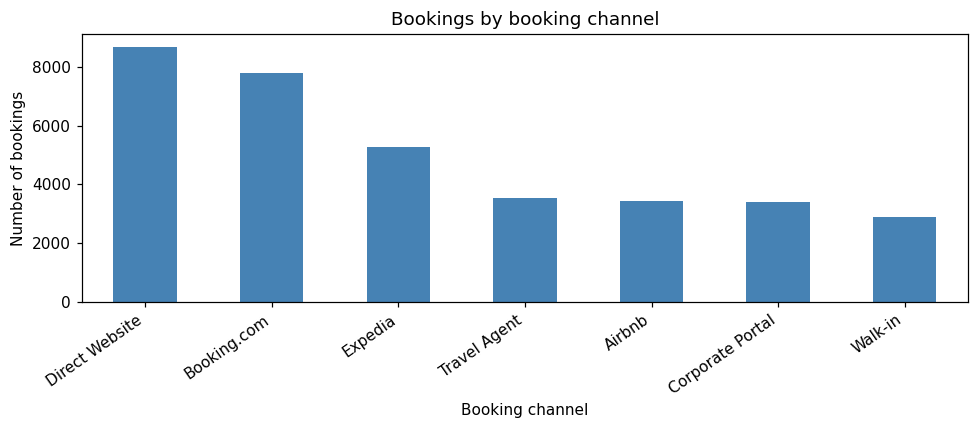

In [20]:
channel_counts = bookings['booking_channel'].value_counts()
channel_volume = channel_counts.rename('bookings').to_frame()
channel_volume['share_percent'] = 100 * channel_volume['bookings'] / len(bookings)
display(channel_volume.round(1))

channel_counts.plot(kind='bar', color='steelblue')
plt.title('Bookings by booking channel')
plt.xlabel('Booking channel')
plt.ylabel('Number of bookings')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

**Direct Website** leads with **8,688 bookings (24.8%)**, followed by **Booking.com with 7,808 (22.3%)**. Together they account for **47.1% of bookings**. Channel volume alone does not include commission costs.

### 4.4 Booking value by channel

,bookings,total_booking_value,average_booking_value,value_share_percent
booking_channel,,,,
Direct Website,8688,4051385.20,466.32,24.84
Booking.com,7808,3654237.93,468.01,22.40
Expedia,5273,2452361.55,465.08,15.03
Travel Agent,3529,1618571.44,458.65,9.92
Corporate Portal,3411,1611396.00,472.41,9.88
Airbnb,3416,1604609.36,469.73,9.84
Walk-in,2875,1319438.23,458.94,8.09


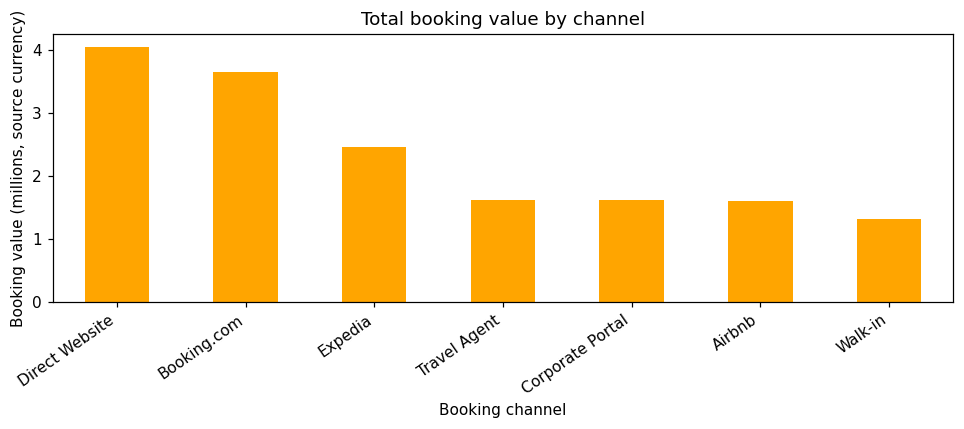

In [21]:
channel_value = bookings.groupby('booking_channel').agg(
    bookings=('booking_id', 'count'),
    total_booking_value=('total_amount', 'sum'),
    average_booking_value=('total_amount', 'mean'),
)
channel_value['value_share_percent'] = 100 * channel_value['total_booking_value'] / bookings['total_amount'].sum()
channel_value = channel_value.sort_values('total_booking_value', ascending=False)
display(channel_value.round(2))

(channel_value['total_booking_value'] / 1_000_000).plot(kind='bar', color='orange')
plt.title('Total booking value by channel')
plt.xlabel('Booking channel')
plt.ylabel('Booking value (millions, source currency)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

**Direct Website contributes 4.05 million (24.8%)**, and **Booking.com 3.65 million (22.4%)**. Average booking value varies only from **458.65 to 472.41** across channels. Their total-value ranking mainly follows booking volume. We cannot rank channel profitability without commissions and other costs.


### 4.5 Stay-duration distribution 

,stay_duration
count,35000.00
mean,2.95
std,1.50
min,1.00
25%,2.00
50%,3.00
75%,4.00
max,7.00


,bookings
stay_duration,
1,5299
2,10425
3,8679
4,5243
5,3614
6,0
7,1740


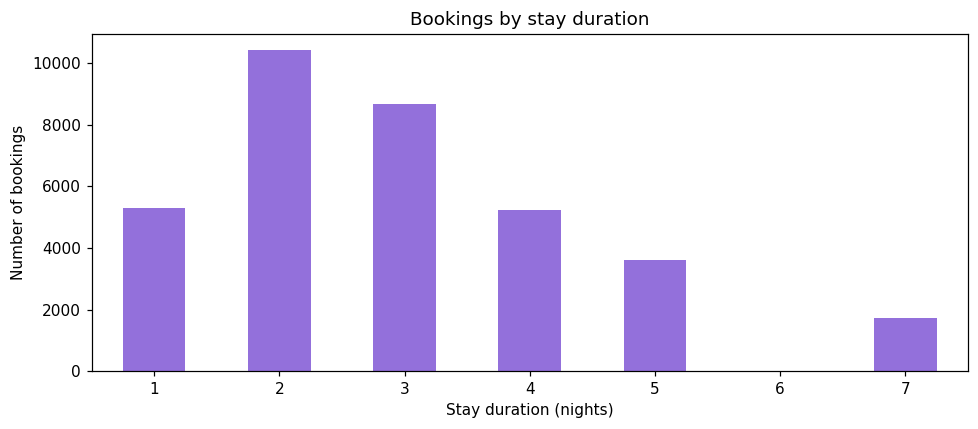

In [22]:
display(bookings['stay_duration'].describe().round(2).to_frame())
stay_counts = bookings['stay_duration'].value_counts().sort_index()
all_durations = range(int(bookings['stay_duration'].min()), int(bookings['stay_duration'].max()) + 1)
stay_counts = stay_counts.reindex(all_durations, fill_value=0)
display(stay_counts.rename('bookings').to_frame())

stay_counts.plot(kind='bar', color='mediumpurple')
plt.title('Bookings by stay duration')
plt.xlabel('Stay duration (nights)')
plt.ylabel('Number of bookings')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Two nights is the most common duration: 10,425 bookings (29.8%)**. The median stay is **3 nights**, the mean is **2.95 nights**, and stays range from **1 to 7 nights**. There are **no six-night stays**, despite 1,740 seven-night stays. Confirm this gap with the data owner; do not manufacture six-night records.


### 4.6 Booking-value distribution

,total_amount
count,35000.00
mean,466.06
std,315.05
min,76.53
25%,241.36
50%,379.59
75%,599.50
max,2447.18


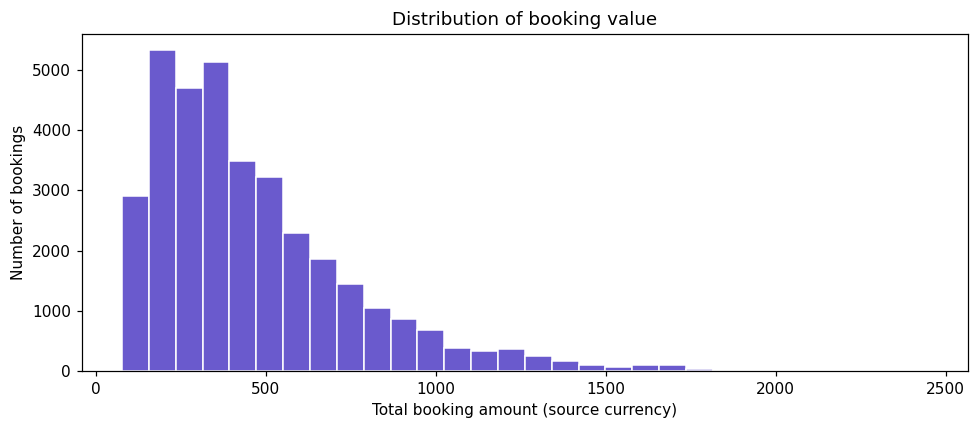

Upper outlier flag: 1136.7
Bookings above that flag: 1551


,booking_id,room_type,stay_duration,total_amount
13,14,Family Room,7,1146.63
35,36,Executive,7,1266.03
40,41,Suite,5,1222.05
60,61,Suite,4,1327.80
116,117,Suite,4,1182.75


In [23]:
display(bookings['total_amount'].describe().round(2).to_frame())
bookings['total_amount'].plot(kind='hist', bins=30, color='slateblue', edgecolor='white')
plt.title('Distribution of booking value')
plt.xlabel('Total booking amount (source currency)')
plt.ylabel('Number of bookings')
plt.tight_layout()
plt.show()

q1 = bookings['total_amount'].quantile(0.25)
q3 = bookings['total_amount'].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
high_value_bookings = bookings[bookings['total_amount'] > upper_limit]
print('Upper outlier flag:', round(upper_limit, 2))
print('Bookings above that flag:', len(high_value_bookings))
display(high_value_bookings[['booking_id', 'room_type', 'stay_duration', 'total_amount']].head())

Booking value has a mean of **466.06**, a median of **379.59** and a maximum of **2,447.18**. The mean above the median indicates a right-skewed distribution. The upper outlier rule flags **1,551 bookings above 1,136.70**. Positive, high amounts are retained because longer or higher-priced stays may explain them; the statistical flag alone is not evidence of error.


### 4.7 Existing sentiment-label distribution

,reviews,share_percent
sentiment_label,,
negative,9863,28.18
neutral,13355,38.16
positive,11782,33.66


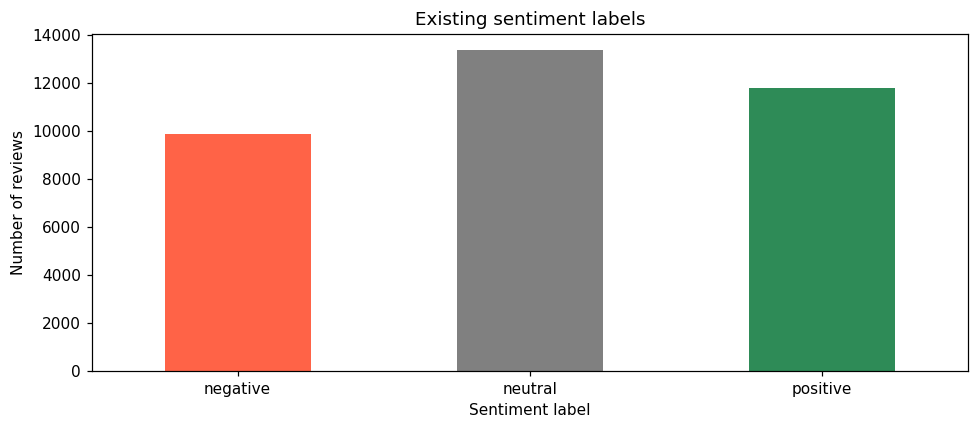

In [24]:
sentiment_order = ['negative', 'neutral', 'positive']
sentiment_counts = analysis['sentiment_label'].value_counts().reindex(sentiment_order, fill_value=0)
sentiment_summary = sentiment_counts.rename('reviews').to_frame()
sentiment_summary['share_percent'] = 100 * sentiment_summary['reviews'] / len(analysis)
display(sentiment_summary.round(2))

sentiment_counts.plot(kind='bar', color=['tomato', 'grey', 'seagreen'])
plt.title('Existing sentiment labels')
plt.xlabel('Sentiment label')
plt.ylabel('Number of reviews')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Neutral: 13,355 (38.2%)**, **positive: 11,782 (33.7%)**, and **negative: 9,863 (28.2%)**. Neutral is the largest category. The three groups are all substantial; these counts describe the supplied labels, whose labelling method still needs confirmation.


### 4.8 Rating distribution and ratings by sentiment

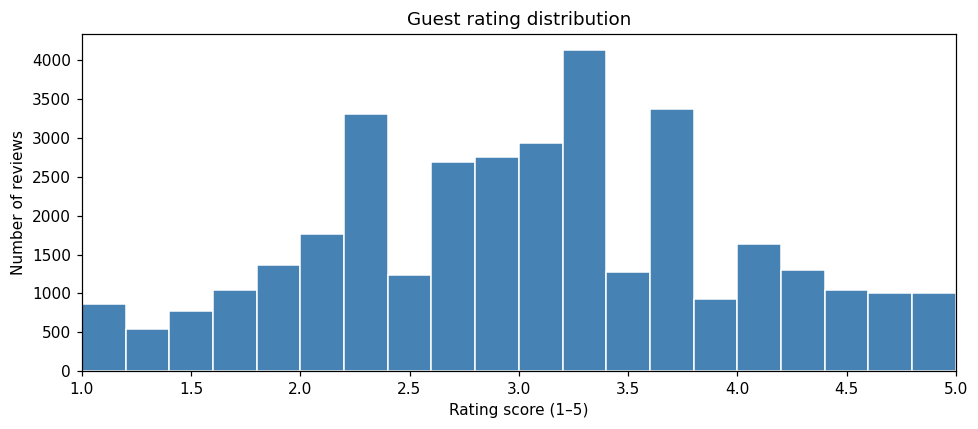

,count,mean,min,max
sentiment_label,,,,
negative,9863,1.94,1.0,3.4
neutral,13355,2.96,1.0,5.0
positive,11782,4.01,2.5,5.0


Overall average rating: 3.03


In [25]:
analysis['rating_score'].plot(kind='hist', bins=20, color='steelblue', edgecolor='white')
plt.title('Guest rating distribution')
plt.xlabel('Rating score (1–5)')
plt.ylabel('Number of reviews')
plt.xlim(1, 5)
plt.tight_layout()
plt.show()

rating_by_sentiment = analysis.groupby('sentiment_label')['rating_score'].agg(['count', 'mean', 'min', 'max'])
display(rating_by_sentiment.reindex(sentiment_order).round(2))
print('Overall average rating:', round(analysis['rating_score'].mean(), 2))

The overall mean rating is **3.03/5**. Average ratings are **1.94 for negative**, **2.96 for neutral** and **4.01 for positive** labels. The ranges overlap: neutral-labelled reviews include scores from 1 to 5, so labels and scores are related but not interchangeable.

### 4.9 Inspect rating-band and sentiment disagreements

In [26]:
label_comparison = pd.crosstab(analysis['sentiment_label'], analysis['rating_band'])
label_comparison = label_comparison.reindex(index=sentiment_order, columns=sentiment_order, fill_value=0)
display(label_comparison)

disagreement_count = analysis['label_rating_disagreement'].sum()
agreement_percent = 100 * (1 - disagreement_count / len(analysis))
print('Agreement with the chosen rating bands:', round(agreement_percent, 2), '%')
print('Flagged disagreements:', disagreement_count)
display(analysis.loc[analysis['label_rating_disagreement'],
                     ['review_id', 'rating_score', 'rating_band', 'sentiment_label', 'review_text']].head(5))

rating_band,negative,neutral,positive
sentiment_label,,,
negative,9320,543,0
neutral,342,12625,388
positive,0,598,11184


Agreement with the chosen rating bands: 94.65 %
Flagged disagreements: 1871


,review_id,rating_score,rating_band,sentiment_label,review_text
34,34,2.7,neutral,positive,"This hotel was a fine, if unremarkable, choice for our time in London. Meanwhile, over..."
40,40,2.8,neutral,negative,"Nothing about our visit to Belfast stood out much either way. Also, i'd describe the r..."
68,67,2.5,neutral,positive,"The cost of the stay was fair, nothing more and nothing less. On the other hand, i'd d..."
76,75,2.6,neutral,negative,I'd describe the overall price as in line with similar hotels — it matched what simila...
108,106,2.9,neutral,positive,I'd describe the breakfast as acceptable — it covered the basics fine. Might consider ...


The labels agree with the chosen bands for **94.65% of reviews**; **1,871 (5.35%)** disagree. These are useful audit cases, but ratings and text may legitimately express different things. We cannot infer a classifier accuracy ceiling or automatically relabel them from this comparison.


### 4.10 Monthly review volume, rating and sentiment

,reviews,average_rating
review_month,,
2025-01,1406,3.03
2025-02,1927,3.02
2025-03,2058,3.01
2025-04,1967,3.02
2025-05,2064,2.99
2025-06,1955,3.06
2025-07,2072,3.04
2025-08,2002,3.05
2025-09,1932,3.05


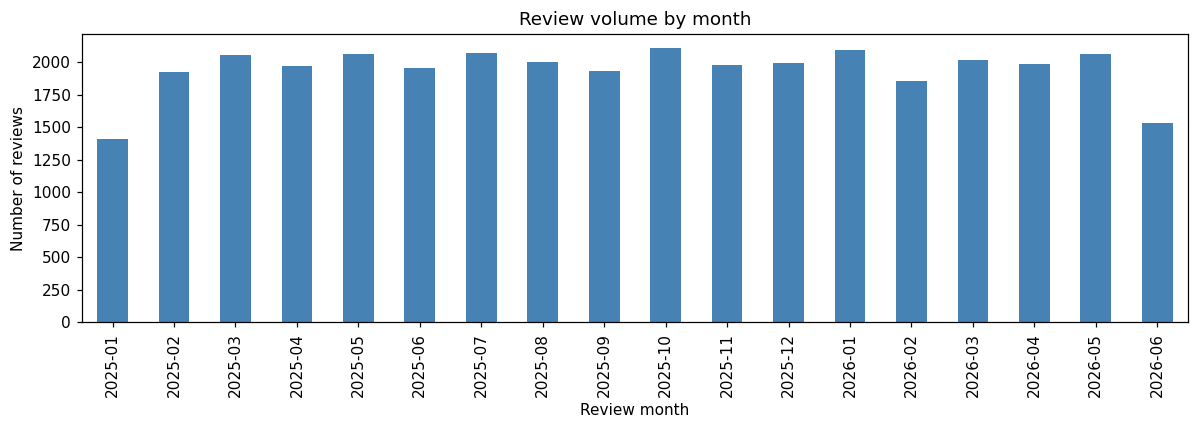

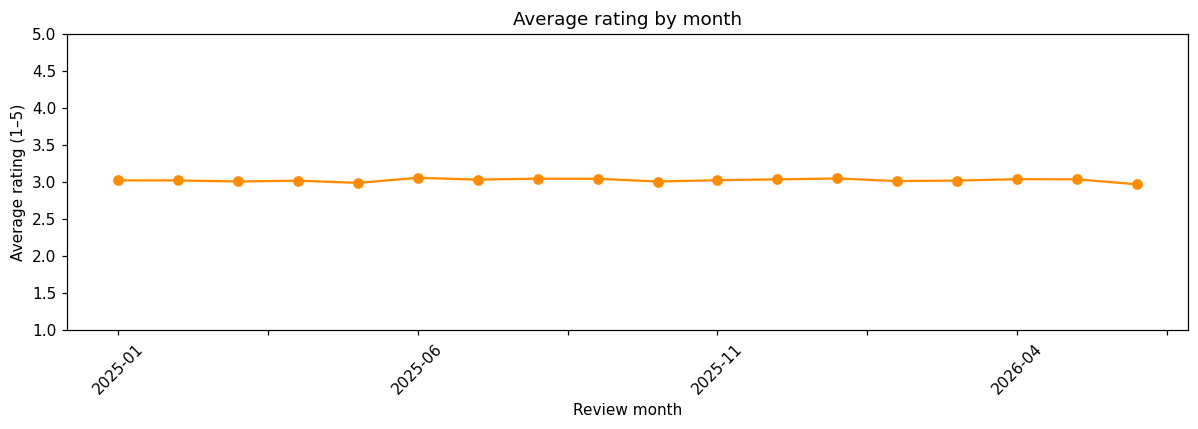

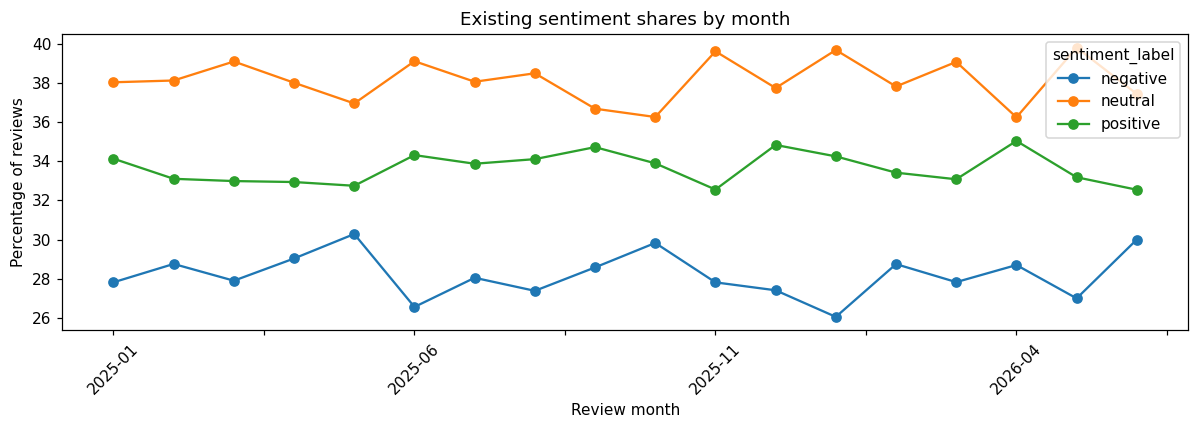

In [27]:
monthly = analysis.groupby('review_month').agg(
    reviews=('review_id', 'count'),
    average_rating=('rating_score', 'mean'),
)
display(monthly.round(2))

monthly['reviews'].plot(kind='bar', color='steelblue', figsize=(11, 4))
plt.title('Review volume by month')
plt.xlabel('Review month')
plt.ylabel('Number of reviews')
plt.tight_layout()
plt.show()

monthly['average_rating'].plot(marker='o', color='darkorange', figsize=(11, 4))
plt.title('Average rating by month')
plt.xlabel('Review month')
plt.ylabel('Average rating (1–5)')
plt.ylim(1, 5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

monthly_sentiment = pd.crosstab(analysis['review_month'], analysis['sentiment_label'], normalize='index') * 100
monthly_sentiment = monthly_sentiment.reindex(columns=sentiment_order)
monthly_sentiment.plot(marker='o', figsize=(11, 4))
plt.title('Existing sentiment shares by month')
plt.xlabel('Review month')
plt.ylabel('Percentage of reviews')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Monthly mean ratings range from **2.97 to 3.06**, showing little movement in the aggregate. **January 2025 has 1,406 reviews and June 2026 has 1,530**, below the roughly 1,900–2,100 seen in most other months. The review-date coverage starts on 2 January and ends on 30 June; lower endpoint volumes alone do not prove both are partial extracts or show a demand decline.

### 4.11 Review length and simple sentence structure

,word_count,character_count,sentence_count_approx
count,35000.00,35000.00,35000.00
mean,29.22,171.91,2.45
std,6.63,39.80,0.61
min,13.00,67.00,1.00
25%,24.00,143.00,2.00
50%,29.00,172.00,2.00
75%,35.00,203.00,3.00
max,40.00,280.00,5.00


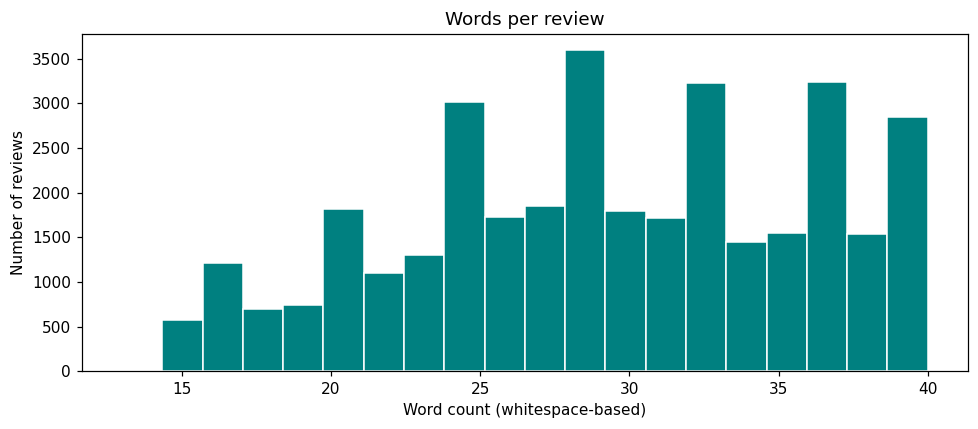

,count,mean,median
sentiment_label,,,
negative,9863,29.25,29.0
neutral,13355,29.23,30.0
positive,11782,29.20,29.0


,reviews
sentence_count_approx,
1,926
2,18521
3,14353
4,1198
5,2


Word count / rating correlation: 0.002


In [28]:
display(analysis[['word_count', 'character_count', 'sentence_count_approx']].describe().round(2))
analysis['word_count'].plot(kind='hist', bins=20, color='teal', edgecolor='white')
plt.title('Words per review')
plt.xlabel('Word count (whitespace-based)')
plt.ylabel('Number of reviews')
plt.tight_layout()
plt.show()

display(analysis.groupby('sentiment_label')['word_count'].agg(['count', 'mean', 'median']).round(2))
display(analysis['sentence_count_approx'].value_counts().sort_index().rename('reviews').to_frame())
print('Word count / rating correlation:', round(analysis['word_count'].corr(analysis['rating_score']), 3))

Reviews are short: **13–40 words**, with a mean of **29.22 words**. Word count has an approximately zero linear correlation with rating. Short, similarly structured wording and repeated texts suggest the source may be templated; provenance should be confirmed. Whitespace word count does not establish transformer token length.

### 4.12 Compare individual hotels

,hotel_id,hotel_label,star_rating,reviews,average_rating,negative_percent
15,16,Glasgow Skyline Hotel (#16),3,1445,2.83,34.88
13,14,Edinburgh Riverside Hotel (#14),3,1422,2.83,35.23
8,9,Edinburgh Riverside Hotel (#9),3,1487,2.84,35.31
16,17,Leicester Harbour Hotel (#17),3,1353,2.85,33.04
23,24,Glasgow Harbour Hotel (#24),3,1385,2.86,33.65
2,3,The Oxford Boutique (#3),3,1405,2.86,34.23
3,4,The Glasgow Heritage (#4),3,1354,2.86,34.93
5,6,The Leeds Grand (#6),3,1373,2.86,33.5
11,12,Manchester Metropolitan (#12),3,1418,2.88,32.93
24,25,The Brighton Heritage (#25),3,1399,2.88,33.24


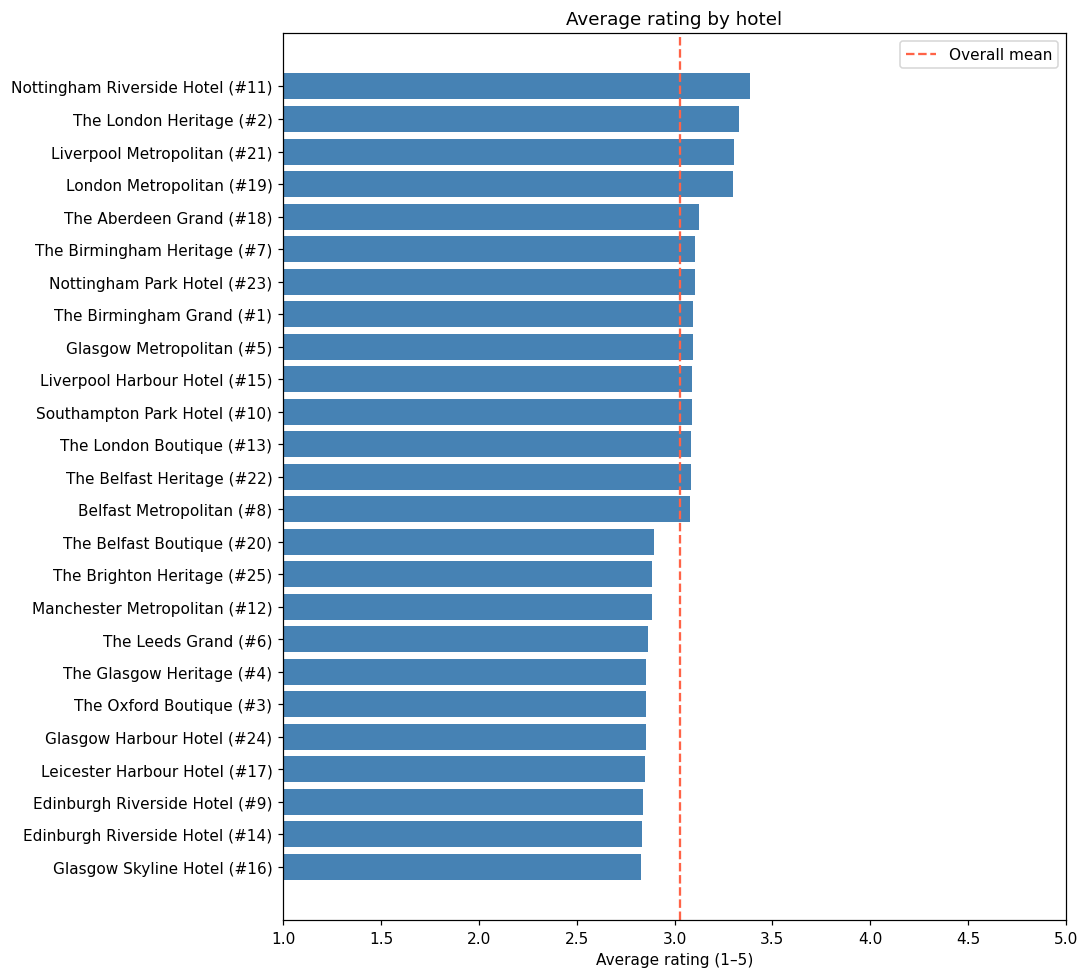

In [29]:
hotel_summary = analysis.groupby(['hotel_id', 'hotel_label', 'star_rating']).agg(
    reviews=('review_id', 'count'),
    average_rating=('rating_score', 'mean'),
    negative_share=('is_negative', 'mean'),
).reset_index()
hotel_summary['negative_percent'] = 100 * hotel_summary['negative_share']
hotel_summary = hotel_summary.sort_values('average_rating')
display(hotel_summary[['hotel_id', 'hotel_label', 'star_rating', 'reviews', 'average_rating', 'negative_percent']].round(2))

plt.figure(figsize=(10, 9))
plt.barh(hotel_summary['hotel_label'], hotel_summary['average_rating'], color='steelblue')
plt.axvline(analysis['rating_score'].mean(), color='tomato', linestyle='--', label='Overall mean')
plt.title('Average rating by hotel')
plt.xlabel('Average rating (1–5)')
plt.xlim(1, 5)
plt.legend()
plt.tight_layout()
plt.show()

**Nottingham Riverside Hotel (#11)** has the highest mean rating (**3.39**, 1,442 reviews), and **Glasgow Skyline Hotel (#16)** the lowest (**2.83**, 1,445 reviews). The difference is **0.56 rating points**. Hotel comparisons reveal larger descriptive differences than most guest or booking categories, but star tier should be considered before drawing management conclusions.

### 4.13 Compare hotel star tiers and cities

,count,mean
star_rating,,
3,15450,2.86
4,14084,3.09
5,5466,3.33


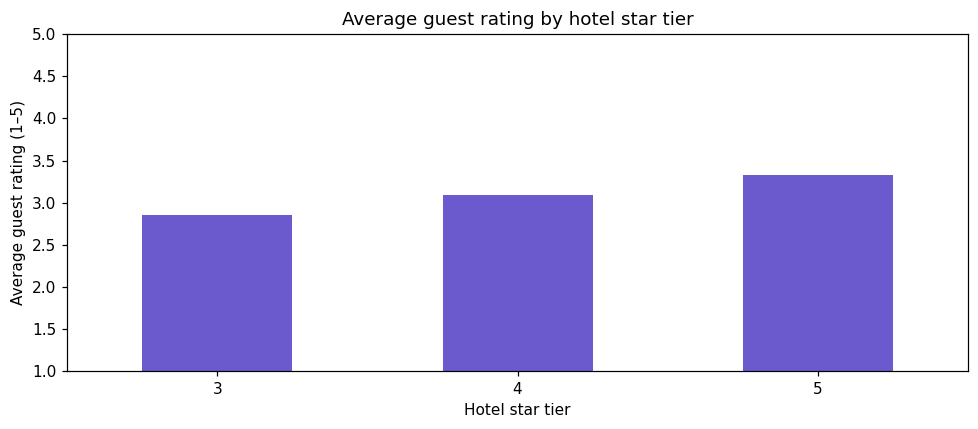

,hotels,reviews,average_rating,negative_percent
location,,,,
Nottingham,2,2872,3.25,20.89
London,3,4145,3.24,21.3
Liverpool,2,2695,3.19,22.89
Aberdeen,1,1362,3.12,24.6
Birmingham,2,2795,3.10,25.3
Southampton,1,1460,3.09,26.03
Belfast,3,4202,3.02,28.39
Glasgow,4,5612,2.91,32.11
Brighton,1,1399,2.88,33.24


In [30]:
star_summary = analysis.groupby('star_rating')['rating_score'].agg(['count', 'mean'])
display(star_summary.round(2))
star_summary['mean'].plot(kind='bar', color='slateblue')
plt.title('Average guest rating by hotel star tier')
plt.xlabel('Hotel star tier')
plt.ylabel('Average guest rating (1–5)')
plt.ylim(1, 5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

city_summary = analysis.groupby('location').agg(
    hotels=('hotel_id', 'nunique'),
    reviews=('review_id', 'count'),
    average_rating=('rating_score', 'mean'),
    negative_share=('is_negative', 'mean'),
).sort_values('average_rating', ascending=False)
city_summary['negative_percent'] = city_summary['negative_share'] * 100
display(city_summary[['hotels', 'reviews', 'average_rating', 'negative_percent']].round(2))

Mean guest ratings increase across hotel tiers: **3-star 2.86**, **4-star 3.09**, **5-star 3.33**. **Nottingham (3.25)** and **London (3.24)** lead the city averages; **Edinburgh (2.84)** is lowest. City comparisons mix different hotels and star tiers, so this does not prove that the city itself causes the difference.


### 4.14 Compare guest groups


Guest grouping: customer_type


,reviews,average_rating,negative_percent
customer_type,,,
Business,8404,3.00,29.27
Corporate,5517,3.02,28.53
Family,3515,3.06,26.94
Group,3564,3.01,28.4
Leisure,14000,3.04,27.64



Guest grouping: loyalty_status


,reviews,average_rating,negative_percent
loyalty_status,,,
Gold,5857,3.02,28.68
Platinum,2923,3.01,27.85
Silver,8605,3.04,28.38
Unknown,17615,3.03,27.97



Guest grouping: country


,reviews,average_rating,negative_percent
country,,,
Australia,173,3.04,28.32
Canada,1242,3.00,28.42
China,185,3.02,27.03
France,2027,3.05,28.12
Germany,2565,3.01,28.34
India,349,3.00,28.37
Ireland,1818,3.01,29.81
Italy,1047,3.03,25.31
Netherlands,1691,3.06,27.32


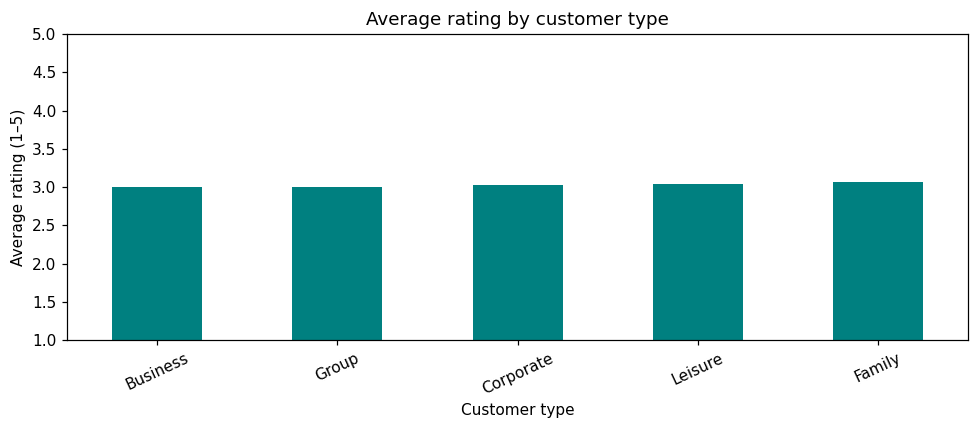

In [31]:
for category in ['customer_type', 'loyalty_status', 'country']:
    guest_summary = analysis.groupby(category).agg(
        reviews=('review_id', 'count'),
        average_rating=('rating_score', 'mean'),
        negative_share=('is_negative', 'mean'),
    )
    guest_summary['negative_percent'] = guest_summary['negative_share'] * 100
    print('\nGuest grouping:', category)
    display(guest_summary[['reviews', 'average_rating', 'negative_percent']].round(2))

customer_ratings = analysis.groupby('customer_type')['rating_score'].mean().sort_values()
customer_ratings.plot(kind='bar', color='teal')
plt.title('Average rating by customer type')
plt.xlabel('Customer type')
plt.ylabel('Average rating (1–5)')
plt.ylim(1, 5)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

Customer-type means range from **3.00 (Business)** to **3.06 (Family)**. Known loyalty-tier means range from **3.01 to 3.04**, while Unknown averages **3.03**. Country means are also close, at roughly **2.99–3.06**. These small aggregate differences do not establish that guest characteristics have no effect in every hotel.

### 4.15 Compare satisfaction across booking characteristics

In [32]:
for category in ['room_type', 'booking_channel', 'stay_duration']:
    booking_ratings = analysis.groupby(category).agg(
        reviews=('review_id', 'count'),
        average_rating=('rating_score', 'mean'),
        negative_share=('is_negative', 'mean'),
    )
    booking_ratings['negative_percent'] = booking_ratings['negative_share'] * 100
    print('\nBooking grouping:', category)
    display(booking_ratings[['reviews', 'average_rating', 'negative_percent']].round(3))

print('Booking amount / rating correlation:', round(analysis['total_amount'].corr(analysis['rating_score']), 3))


Booking grouping: room_type


,reviews,average_rating,negative_percent
room_type,,,
Deluxe,8619,3.037,28.112
Executive,5293,3.031,28.15
Family Room,4137,3.023,28.91
Standard,10596,3.025,28.096
Suite,3544,3.007,28.188
Twin,2811,3.032,27.677



Booking grouping: booking_channel


,reviews,average_rating,negative_percent
booking_channel,,,
Airbnb,3416,3.029,28.542
Booking.com,7808,3.034,28.023
Corporate Portal,3411,3.034,28.232
Direct Website,8688,3.022,27.866
Expedia,5273,3.036,27.385
Travel Agent,3529,3.013,29.215
Walk-in,2875,3.021,29.252



Booking grouping: stay_duration


,reviews,average_rating,negative_percent
stay_duration,,,
1,5299,3.020,28.175
2,10425,3.024,28.422
3,8679,3.022,28.54
4,5243,3.039,27.37
5,3614,3.034,28.141
7,1740,3.054,27.471


Booking amount / rating correlation: 0.003


Average scores are similar across **room types (3.01–3.04)**, **channels (3.01–3.04)** and **stay durations (3.02–3.05)**. Booking amount and score have near-zero linear correlation (**r = 0.003**). Suites have higher average booking value but not higher average satisfaction. This is an aggregate comparison, not a causal test.

### 4.16 Explore common words in each sentiment group

In [33]:
common_filler_words = ['the', 'a', 'an', 'and', 'to', 'of', 'was', 'were', 'is', 'it', 'we', 'for', 'in', 'our', 'on', 'that', 'with', 'as', 'this']
for sentiment in sentiment_order:
    selected_text = analysis.loc[analysis['sentiment_label'] == sentiment, 'text_clean']
    words = selected_text.str.split().explode()
    words = words.str.strip('.,!?;:-()"')
    words = words[words.str.contains('[a-z]', regex=True)]
    words = words[words.ne('') & ~words.isin(common_filler_words)]
    print('\nMost frequent words in', sentiment, 'reviews (occurrences):')
    display(words.value_counts().head(12).rename('occurrences').to_frame())


Most frequent words in negative reviews (occurrences):


,occurrences
text_clean,
be,6066
stay,4497
out,3894
disappointed,3451
left,3169
turned,2925
sadly,2925
which,2860
really,2860



Most frequent words in neutral reviews (occurrences):


,occurrences
text_clean,
nothing,18941
what,13270
about,9729
overall,7471
more,6921
paid,6820
expected,6728
fine,6668
less,5678



Most frequent words in positive reviews (occurrences):


,occurrences
text_clean,
genuinely,4276
out,3682
stay,3542
honestly,3521
i,3272
impressed,3272
stood,3224
nothing,3172
time,2937


Negative-labelled reviews frequently include **disappointed**, **sadly** and **affected**. Neutral-labelled reviews frequently include **expected** and **fine**; positive-labelled reviews include **genuinely**, **impressed**, **exceeded** and **expectations**. These words give an initial sense of the wording, but generic words such as stay occur across labels. Group sizes differ, so raw word counts are not a measure of distinctiveness or a verified topic classification.


### 4.17 Check negation and contrast wording

In [34]:
language_flags = pd.DataFrame({
    'sentiment_label': analysis['sentiment_label'],
    'contains_negation': analysis['text_clean'].str.contains(r"\b(?:not|no|never|cannot)\b|n't", regex=True),
    'contains_contrast': analysis['text_clean'].str.contains(r'\b(?:but|however|although)\b', regex=True),
})
language_percent = language_flags.groupby('sentiment_label')[['contains_negation', 'contains_contrast']].mean() * 100
display(language_percent.reindex(sentiment_order).round(1))

,contains_negation,contains_contrast
sentiment_label,,
negative,47.9,13.1
neutral,18.5,18.6
positive,12.4,4.1


Selected negation occurs in **47.9% of negative**, **18.5% of neutral** and **12.4% of positive** reviews. Contrast wording occurs in **13.1%**, **18.6%** and **4.1%**, respectively. This supports keeping negation during cleaning. A negation word or connector alone does not establish negative or mixed sentiment: “not bad” and “not clean” have different meanings, and context still matters.


### 4.18 Correlations between numeric fields

,rating_score,word_count,stay_duration,total_amount,previous_stays,star_rating,total_rooms
rating_score,1.000,0.002,0.008,0.003,0.007,0.182,0.074
word_count,0.002,1.000,-0.009,-0.013,-0.005,0.011,0.003
stay_duration,0.008,-0.009,1.000,0.753,0.010,0.002,0.002
total_amount,0.003,-0.013,0.753,1.000,0.010,-0.004,-0.005
previous_stays,0.007,-0.005,0.010,0.010,1.000,-0.010,0.002
star_rating,0.182,0.011,0.002,-0.004,-0.010,1.000,0.406
total_rooms,0.074,0.003,0.002,-0.005,0.002,0.406,1.000


,correlation_with_rating
word_count,0.002
stay_duration,0.008
total_amount,0.003
previous_stays,0.007
star_rating,0.182
total_rooms,0.074


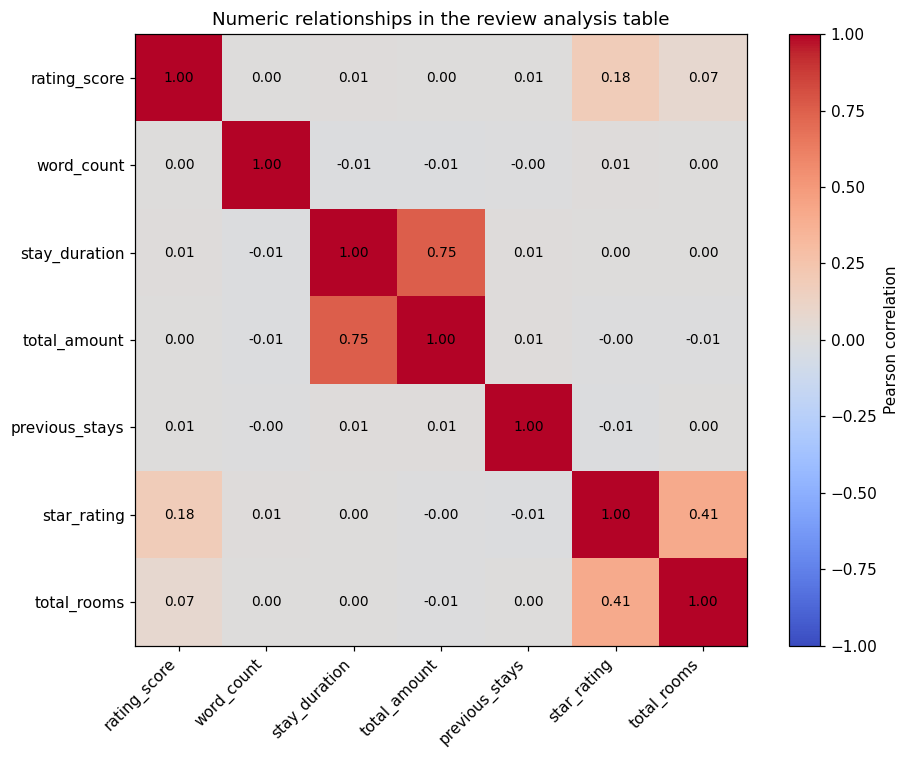

In [35]:
numeric_columns = ['rating_score', 'word_count', 'stay_duration', 'total_amount', 'previous_stays', 'star_rating', 'total_rooms']
correlations = analysis[numeric_columns].corr()
display(correlations.round(3))
display(correlations['rating_score'].drop('rating_score').rename('correlation_with_rating').to_frame().round(3))

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlations, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_columns)), labels=numeric_columns, rotation=45, ha='right')
ax.set_yticks(range(len(numeric_columns)), labels=numeric_columns)
for row in range(len(numeric_columns)):
    for column in range(len(numeric_columns)):
        ax.text(column, row, f'{correlations.iloc[row, column]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(image, ax=ax, label='Pearson correlation')
ax.set_title('Numeric relationships in the review analysis table')
plt.tight_layout()
plt.show()

Guest rating has a **weak positive linear association with star tier (r = 0.182)** and a smaller one with hotel room count (**0.074**). Booking amount, stay duration, previous stays and word count are near zero. Stay duration and booking amount have a stronger positive association (**r = 0.754**), which is consistent with longer stays often costing more. These results describe simple pairwise relationships; they do not prove the hotel tier causes higher scores or that all useful explanations must be in the text.

### Phase 4 — Findings to present

| Area | Checked finding | Practical interpretation |
|---|---|---|
| Data coverage | 35,000 reviews; 25 hotels; 14 cities; 11,377 reviewing guests | We have linked review and stay context |
| Data quality | Source keys and links pass; 6,036 guest loyalty values are missing | Keep Unknown loyalty and confirm its meaning |
| Booking mix | Standard rooms are 30.3% of bookings; Deluxe contributes the most booking value | Volume and value answer different questions |
| Channels | Direct Website and Booking.com are 47.1% of bookings | Large channels matter commercially; costs still need checking |
| Stay duration | Median 3 nights; mode 2 nights; no six-night stays | Investigate the gap with the data owner |
| Sentiment | Neutral 38.2%; positive 33.7%; negative 28.2% | Describe existing labels; confirm how they were assigned |
| Ratings and labels | 5.35% disagree with the chosen rating bands | Audit examples; do not automatically change labels |
| Hotel differences | Hotel averages range from 2.83 to 3.39 | Compare hotels while considering star tier |
| Guest and booking groups | Most group means are close to 3.0 | Aggregate segments show limited differentiation here |
| Text quality | Repeated complete reviews and conflicting text labels exist | Flag them and confirm data provenance before later modelling |

### Questions to take back to the data owner
- Does missing loyalty mean no membership or simply unrecorded information?
- What currency does `total_amount` use, and does it include refunds, cancellations, taxes or channel commission?
- Why are six-night stays absent?
- Are the reviews live guest feedback, generated examples or templated data?
- How were the sentiment labels created, and what should happen when identical text carries different labels?
- Are the endpoint review months fully captured, and why does every booking currently have exactly one review?

### Limits of the findings
These summaries describe the uploaded snapshots. We do not test statistical significance, control jointly for hotel and guest factors, identify causal effects, predict sentiment, or identify topics. The notebook does not verify the source provenance. Individual reviews and business rules still need inspection before acting on aggregate patterns.

### My closing explanation
> I collected four source tables, checked and prepared the data, and joined the records without losing reviews. I then explored booking mix and guest experience. The largest descriptive score differences are between hotels and hotel tiers, while many guest and booking groups look similar at portfolio level. I also identified data questions that need confirmation before moving to deeper text analysis. This notebook stops at data preparation and EDA.

**Next stage, outside this notebook:** after confirming the data questions, consider topic and sentiment analysis with a carefully designed evaluation. No later-phase results from the original advanced notebook are claimed here.